In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

# Loading the dataset
The torchvision library contains the MNIST dataset

In [2]:
mnist_trainset = DataLoader(datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor()),batch_size = 128,shuffle=False)
mnist_testset = DataLoader(datasets.MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor()),batch_size = 128,shuffle=False)


The dataset is split into the training and test dataset with sizes:

In [3]:
print(len(mnist_trainset))
print(len(mnist_testset))

469
79


# Baseline CNN Model

The baseline has 2 convolutional layers and a max pooling. 

In [4]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN,self).__init__()
        self.conv1 = nn.Conv2d(1,16,5)
        self.conv2 = nn.Conv2d(16,32,5)

        self.pool = nn.MaxPool2d(2,2)
        self.fc = nn.Linear(2048,10)
        
    def forward(self,x):
        x = self.conv1(x)
        x = F.relu(x)
        
        x = self.pool(x)

        x = F.relu(x)
        x = self.conv2(x)

        x = x.reshape(x.size(0), -1)
        x = self.fc(x)

        return x


Training Function

In [5]:

def train(model,dataloader,optimizer,criterion,max_epochs=10,loss_threshold=0.05):
    loss_history = []
    for epoch in range(max_epochs):

        running_loss = 0.0
        for inputs, labels in mnist_trainset:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        avg_loss = running_loss / len(mnist_trainset)
        loss_history.append(avg_loss)

        print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")
        if avg_loss < loss_threshold:
            print(f"Loss threshold reached at epoch {epoch+1}, stopping early.")
            break
    return loss_history


Training the Baseline CNN model


In [6]:
baseline_model = BaselineCNN()
baseline_criterion = nn.CrossEntropyLoss()
baseline_optimizer = torch.optim.SGD(baseline_model.parameters(), lr=0.01)

#Default 
max_epoch = 10
loss_threshold = 0.05
baseline_training_loss = train(baseline_model,mnist_trainset,baseline_optimizer,baseline_criterion,max_epochs=max_epoch,loss_threshold=loss_threshold)


Epoch 1, Loss: 0.7719
Epoch 2, Loss: 0.3684
Epoch 3, Loss: 0.3348
Epoch 4, Loss: 0.3057
Epoch 5, Loss: 0.2695
Epoch 6, Loss: 0.2286
Epoch 7, Loss: 0.1939
Epoch 8, Loss: 0.1689
Epoch 9, Loss: 0.1513
Epoch 10, Loss: 0.1384


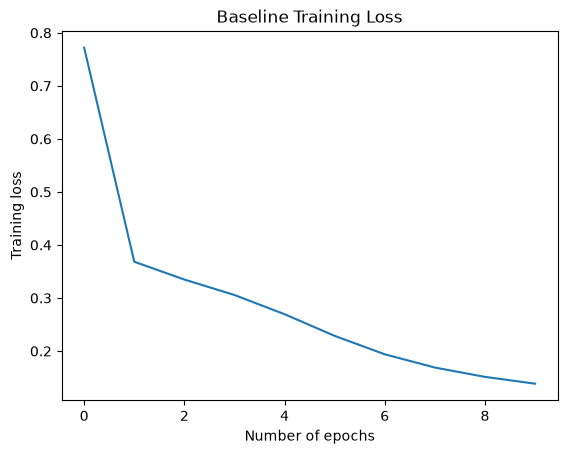

In [7]:
plt.plot(range(len(baseline_training_loss)), baseline_training_loss)
plt.title("Baseline Training Loss")
plt.xlabel("Number of epochs")
plt.ylabel("Training loss")
plt.show()

In [8]:
validation_loss = []
def evaluate(model,dataloader,criterion):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0.0
    with torch.no_grad():
        for images, labels in dataloader:
            outputs = model(images)
            loss = criterion(outputs,labels)
            total_loss += loss.item()

            _, predicted = torch.max(outputs, 1)  # class with highest score
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    accuracy = correct / total
    avg_loss = total_loss / len(dataloader)
    validation_loss.append(avg_loss)

    print(f"Test Loss: {avg_loss:.4f}, Test Accuracy: {accuracy:.4f}")
    # return accuracy, avg_loss


evaluate(baseline_model, mnist_testset,baseline_criterion)

Test Loss: 0.1192, Test Accuracy: 0.9645


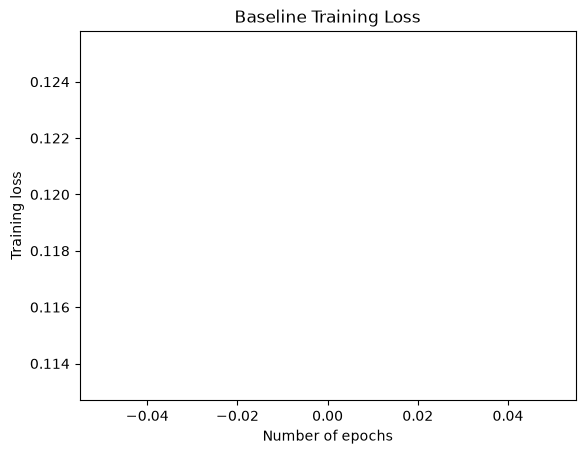

In [9]:
plt.plot(range(len(validation_loss)), validation_loss)
# print(len(loss_history))
plt.title("Baseline Training Loss")
plt.xlabel("Number of epochs")
plt.ylabel("Training loss")
plt.show()